# Notebook 09A - Independent Verification of Frozen Model B — MURA XR_WRIST

## STEP 0 — Purpose and Validation Scope

### Objective

This notebook independently verifies the predictions produced by the frozen Model B (fine-tuned ResNet-18) for three XR_WRIST studies previously processed in Notebook 09 (Agentic AI).

The verification is performed **outside the CrewAI agent workflow**, without Gemini, agent tools, or LLM-based decision-making.

### Verification Goals

1. Confirm that the original frozen Model B checkpoint and preprocessing pipeline reproduce the recorded image-level and study-level predictions.
2. Verify that the frozen classification threshold and mean-probability aggregation rule are preserved.
3. Compare model predictions against original Stanford MURA ground-truth study labels.
4. Analyze the false-positive prediction observed in `MURA_WRIST_RANDOM_001`, including image-level threshold disagreement.
5. Distinguish model inference, deterministic workflow policy, and agent-generated explanations.

#### Studies Evaluated

| Study alias | Original MURA study | Images | Ground truth |
|---|---|---:|---|
| MURA_WRIST_RANDOM_001 | valid/XR_WRIST/patient11212/study2_negative | 3 | NORMAL |
| MURA_WRIST_RANDOM_002 | valid/XR_WRIST/patient11254/study1_positive | 3 | ABNORMAL |
| MURA_WRIST_NO_TOOLS_001 | valid/XR_WRIST/patient11313/study1_negative | 2 | NORMAL |

**NO_TOOLS Image Identity Verification:** Both images of `MURA_WRIST_NO_TOOLS_001` were independently verified against the original Stanford MURA ZIP archive. Although the file-level SHA256 hashes differed, the decoded grayscale pixel arrays were identical for both images (425 × 512 pixels). Therefore, the original study mapping and NORMAL ground-truth label were confirmed.

The frozen Model B predicted NORMAL for this study (study probability: 0.001947), resulting in a **True Negative** classification.

### Frozen Operating Policy

- Model: Fine-tuned ResNet-18 (Model B)
- Classification threshold: `0.263567715883255`
- Study aggregation: `mean_probability`
- Model weights: Frozen; no training or fine-tuning
- Inference mode: `eval()` with gradients disabled

### Validation Boundaries

This is a focused reproducibility and case-analysis exercise involving three selected studies, not a new evaluation of population-level model performance.

The official MURA validation split is used only for ground-truth verification and retrospective analysis. No threshold tuning, model selection, or retraining is performed.

All outputs are research-only and are not intended for clinical diagnosis or autonomous medical decision-making.

In [1]:
# @title
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# @title

from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Final Project DS23/"
    "Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays"
)

GRADCAM_DIR = PROJECT_ROOT / "DATA" / "GRADCAM_VALIDATION"

STUDIES = {
    "MURA_WRIST_RANDOM_001": 3,
    "MURA_WRIST_RANDOM_002": 3,
    "MURA_WRIST_NO_TOOLS_001": 2,
}

study_images = {}

for study_id, expected_count in STUDIES.items():
    folder = GRADCAM_DIR / study_id
    images = sorted(folder.glob("*_original.png"))

    assert len(images) == expected_count, (
        f"{study_id}: expected {expected_count} images, "
        f"found {len(images)}"
    )

    study_images[study_id] = images

    print(f"{study_id}: {len(images)} images")
    for image_path in images:
        print(f"  {image_path.name}")

print("\nSTEP 1 PASSED — All 8 original images found.")


MURA_WRIST_RANDOM_001: 3 images
  image_01_original.png
  image_02_original.png
  image_03_original.png
MURA_WRIST_RANDOM_002: 3 images
  image_01_original.png
  image_02_original.png
  image_03_original.png
MURA_WRIST_NO_TOOLS_001: 2 images
  image1_original.png
  image2_original.png

STEP 1 PASSED — All 8 original images found.


In [3]:
# @title

from pathlib import Path
import json

MODEL_DIR = PROJECT_ROOT / "DATA" / "MODEL_B_FINE_TUNING"

CHECKPOINT_PATH = MODEL_DIR / "best_resnet18_study_level.pt"
POLICY_PATH = MODEL_DIR / "frozen_primary_operating_policy.json"

print("STEP 2 — FROZEN MODEL B ARTIFACT CHECK")
print("=" * 55)

print("Model directory:", MODEL_DIR)
print("Checkpoint exists:", CHECKPOINT_PATH.is_file())
print("Frozen policy exists:", POLICY_PATH.is_file())

assert CHECKPOINT_PATH.is_file(), (
    f"Canonical checkpoint not found: {CHECKPOINT_PATH}"
)
assert POLICY_PATH.is_file(), (
    f"Frozen operating policy not found: {POLICY_PATH}"
)

with open(POLICY_PATH, encoding="utf-8") as f:
    frozen_policy = json.load(f)

FROZEN_THRESHOLD = float(frozen_policy["threshold"])

assert abs(FROZEN_THRESHOLD - 0.263567715883255) < 1e-12
assert frozen_policy["study_aggregation"] == "mean_probability"

print("\nFrozen threshold:", FROZEN_THRESHOLD)
print("Aggregation:", frozen_policy["study_aggregation"])
print("Checkpoint size (MB):",
      round(CHECKPOINT_PATH.stat().st_size / 1024**2, 2))

print("\nSTEP 2 PASSED — Frozen Model B artifacts verified.")


STEP 2 — FROZEN MODEL B ARTIFACT CHECK
Model directory: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/MODEL_B_FINE_TUNING
Checkpoint exists: True
Frozen policy exists: True

Frozen threshold: 0.263567715883255
Aggregation: mean_probability
Checkpoint size (MB): 128.05

STEP 2 PASSED — Frozen Model B artifacts verified.


In [4]:
# @title

# STEP 3 — LOAD FROZEN MODEL B
# Independent validation — no CrewAI, no training

import torch
import torch.nn as nn
from torchvision import models

print("STEP 3 — LOAD FROZEN MODEL B")
print("=" * 55)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class MURAResNet18(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = models.resnet18(weights=None)
        self.backbone.fc = nn.Linear(
            self.backbone.fc.in_features, 1
        )

    def forward(self, x):
        return self.backbone(x)

model_b = MURAResNet18()

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

assert isinstance(checkpoint, dict)
assert "model_state_dict" in checkpoint
assert int(checkpoint["epoch"]) == 9, (
    "Unexpected checkpoint epoch"
)

model_b.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

del checkpoint

model_b = model_b.to(device)
model_b.eval()

for parameter in model_b.parameters():
    parameter.requires_grad = False

total_parameters = sum(
    p.numel() for p in model_b.parameters()
)
trainable_parameters = sum(
    p.numel() for p in model_b.parameters()
    if p.requires_grad
)

assert total_parameters == 11177025
assert trainable_parameters == 0
assert not model_b.training

print("Device:", device)
print("Architecture: ResNet18")
print("Checkpoint epoch: 9")
print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)
print("Evaluation mode:", not model_b.training)
print("Frozen threshold:", FROZEN_THRESHOLD)

print("\nSTEP 3 PASSED — Frozen Model B loaded.")


STEP 3 — LOAD FROZEN MODEL B
Device: cpu
Architecture: ResNet18
Checkpoint epoch: 9
Total parameters: 11177025
Trainable parameters: 0
Evaluation mode: True
Frozen threshold: 0.263567715883255

STEP 3 PASSED — Frozen Model B loaded.


In [5]:
# @title

# STEP 4 — LOAD CANONICAL PREPROCESSING

import sys
import importlib.util
import torch
from PIL import Image

TRANSFORMS_PATH = (
    PROJECT_ROOT / "DATA" / "BASELINE_MODEL_A" / "transforms.py"
)

print("STEP 4 — CANONICAL PREPROCESSING")
print("=" * 55)
print("Transforms path:", TRANSFORMS_PATH)
print("File exists:", TRANSFORMS_PATH.is_file())

assert TRANSFORMS_PATH.is_file(), (
    f"Canonical transforms.py not found: {TRANSFORMS_PATH}"
)

spec = importlib.util.spec_from_file_location(
    "mura_canonical_transforms",
    TRANSFORMS_PATH
)

assert spec is not None and spec.loader is not None

mura_transforms = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = mura_transforms
spec.loader.exec_module(mura_transforms)

assert hasattr(mura_transforms, "build_eval_transform"), (
    "Canonical build_eval_transform() not found."
)

inference_transform = mura_transforms.build_eval_transform()

# Verify preprocessing on a synthetic image
synthetic_image = Image.new("L", (300, 200), color=128)
transformed = inference_transform(synthetic_image)

assert tuple(transformed.shape) == (3, 224, 224)
assert torch.isfinite(transformed).all()

print("Output shape:", tuple(transformed.shape))
print("Finite values:", bool(torch.isfinite(transformed).all()))
print("Model evaluation mode:", not model_b.training)

print("\nSTEP 4 PASSED — Canonical preprocessing loaded.")


STEP 4 — CANONICAL PREPROCESSING
Transforms path: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/BASELINE_MODEL_A/transforms.py
File exists: True
Output shape: (3, 224, 224)
Finite values: True
Model evaluation mode: True

STEP 4 PASSED — Canonical preprocessing loaded.


In [6]:
# @title

# STEP 5 — INDEPENDENT MODEL B INFERENCE

import pandas as pd
import numpy as np
import torch
from PIL import Image

print("STEP 5 — INDEPENDENT MODEL B INFERENCE")
print("=" * 60)

results = []

assert not model_b.training

with torch.inference_mode():
    for study_id, image_paths in study_images.items():
        for image_path in image_paths:

            with Image.open(image_path) as img:
                image = img.convert("L")
                tensor = inference_transform(image)

            assert tensor.shape == (3, 224, 224)

            tensor = tensor.unsqueeze(0).to(device)

            logits = model_b(tensor)
            probability = torch.sigmoid(logits).item()

            assert np.isfinite(probability)
            assert 0 <= probability <= 1

            results.append({
                "study_id": study_id,
                "image": image_path.name,
                "probability": probability,
                "image_prediction": int(
                    probability >= FROZEN_THRESHOLD
                )
            })

df_inference = pd.DataFrame(results)

assert len(df_inference) == 8

df_studies = (
    df_inference
    .groupby("study_id", as_index=False)
    .agg(
        n_images=("image", "count"),
        study_probability=("probability", "mean")
    )
)

df_studies["study_prediction"] = (
    df_studies["study_probability"] >= FROZEN_THRESHOLD
).astype(int)

df_studies["classification"] = (
    df_studies["study_prediction"]
    .map({0: "NORMAL", 1: "ABNORMAL"})
)

print("\nIMAGE-LEVEL RESULTS")
display(df_inference)

print("\nSTUDY-LEVEL RESULTS")
display(df_studies)

print("\nSTEP 5 PASSED — Independent inference completed.")


STEP 5 — INDEPENDENT MODEL B INFERENCE

IMAGE-LEVEL RESULTS


,study_id,image,probability,image_prediction
0,MURA_WRIST_RANDOM_001,image_01_original.png,0.986073,1
1,MURA_WRIST_RANDOM_001,image_02_original.png,0.058780,0
2,MURA_WRIST_RANDOM_001,image_03_original.png,0.171641,0
3,MURA_WRIST_RANDOM_002,image_01_original.png,0.997911,1
4,MURA_WRIST_RANDOM_002,image_02_original.png,0.997783,1
5,MURA_WRIST_RANDOM_002,image_03_original.png,0.992542,1
6,MURA_WRIST_NO_TOOLS_001,image1_original.png,0.002037,0
7,MURA_WRIST_NO_TOOLS_001,image2_original.png,0.001858,0



STUDY-LEVEL RESULTS


,study_id,n_images,study_probability,study_prediction,classification
0,MURA_WRIST_NO_TOOLS_001,2,0.001947,0,NORMAL
1,MURA_WRIST_RANDOM_001,3,0.405498,1,ABNORMAL
2,MURA_WRIST_RANDOM_002,3,0.996079,1,ABNORMAL



STEP 5 PASSED — Independent inference completed.


In [7]:
# @title

# STEP 6 — VERIFY NUMERICAL AGREEMENT

import numpy as np
import pandas as pd

reference = {
    "MURA_WRIST_RANDOM_001": [
        0.986073, 0.058780, 0.171641
    ],
    "MURA_WRIST_RANDOM_002": [
        0.997911, 0.997783, 0.992542
    ],
    "MURA_WRIST_NO_TOOLS_001": [
        0.002037, 0.001858
    ]
}

rows = []

for study_id, expected in reference.items():
    actual = (
        df_inference.loc[
            df_inference["study_id"] == study_id,
            "probability"
        ]
        .to_numpy()
    )

    assert len(actual) == len(expected)

    for i, (a, e) in enumerate(zip(actual, expected), 1):
        rows.append({
            "study_id": study_id,
            "image_number": i,
            "actual": a,
            "reference": e,
            "absolute_difference": abs(a - e),
            "match": bool(np.isclose(
                a, e, atol=1e-5, rtol=0
            ))
        })

df_comparison = pd.DataFrame(rows)

display(df_comparison)

assert df_comparison["match"].all(), (
    "Numerical disagreement detected."
)

print("Maximum absolute difference:",
      df_comparison["absolute_difference"].max())

print("\nSTEP 6 PASSED — All 8 predictions reproduced.")


,study_id,image_number,actual,reference,absolute_difference,match
0,MURA_WRIST_RANDOM_001,1,0.986073,0.986073,3.747482e-07,True
1,MURA_WRIST_RANDOM_001,2,0.058780,0.058780,4.429233e-07,True
2,MURA_WRIST_RANDOM_001,3,0.171641,0.171641,4.399691e-07,True
3,MURA_WRIST_RANDOM_002,1,0.997911,0.997911,3.936424e-07,True
4,MURA_WRIST_RANDOM_002,2,0.997783,0.997783,1.139717e-07,True
5,MURA_WRIST_RANDOM_002,3,0.992542,0.992542,2.099915e-07,True
6,MURA_WRIST_NO_TOOLS_001,1,0.002037,0.002037,3.633597e-07,True
7,MURA_WRIST_NO_TOOLS_001,2,0.001858,0.001858,4.813159e-07,True


Maximum absolute difference: 4.813158810139297e-07

STEP 6 PASSED — All 8 predictions reproduced.


In [14]:
# @title

# STEP 7 — GROUND TRUTH AND CLASSIFICATION OUTCOMES
# No model inference. No agent execution.

import pandas as pd

study_mapping = {
    "MURA_WRIST_RANDOM_001": {
        "original_study": "valid/XR_WRIST/patient11212/study2_negative",
        "ground_truth": 0,
        "mapping_source": "Notebook 09 — STEP 80A",
        "identity_status": "VERIFIED_MAPPING",
    },
    "MURA_WRIST_RANDOM_002": {
        "original_study": "valid/XR_WRIST/patient11254/study1_positive",
        "ground_truth": 1,
        "mapping_source": "Notebook 09 — STEP 80A",
        "identity_status": "VERIFIED_MAPPING",
    },
    "MURA_WRIST_NO_TOOLS_001": {
        "original_study": "valid/XR_WRIST/patient11313/study1_negative",
        "ground_truth": 0,
        "mapping_source": "Notebook 09 — STEP 70BB",
        "identity_status": "VERIFIED_MAPPING",
    },
}

outcome_names = {
    (0, 0): "True Negative",
    (0, 1): "False Positive",
    (1, 0): "False Negative",
    (1, 1): "True Positive",
}

records = []

for study_id, metadata in study_mapping.items():
    match = df_studies.loc[df_studies["study_id"] == study_id]

    assert len(match) == 1, f"Missing or duplicate study: {study_id}"

    result = match.iloc[0]
    prediction = int(result["study_prediction"])
    ground_truth = metadata["ground_truth"]

    records.append({
        "study_id": study_id,
        "original_study": metadata["original_study"],
        "ground_truth": ground_truth,
        "model_b_probability": float(result["study_probability"]),
        "model_b_prediction": prediction,
        "classification_outcome": outcome_names[
            (ground_truth, prediction)
        ],
        "identity_status": metadata["identity_status"],
        "mapping_source": metadata["mapping_source"],
    })

df_ground_truth = pd.DataFrame(records)

display(df_ground_truth)

assert len(df_ground_truth) == 3

print("\nSTEP 7 PASSED — Ground truth mapping table created.")
print(
    "NO_TOOLS image identity verified against the original "
    "MURA ZIP archive in STEP 7A."
)


,study_id,original_study,ground_truth,model_b_probability,model_b_prediction,classification_outcome,identity_status,mapping_source
0,MURA_WRIST_RANDOM_001,valid/XR_WRIST/patient11212/study2_negative,0,0.405498,1,False Positive,VERIFIED_MAPPING,Notebook 09 — STEP 80A
1,MURA_WRIST_RANDOM_002,valid/XR_WRIST/patient11254/study1_positive,1,0.996079,1,True Positive,VERIFIED_MAPPING,Notebook 09 — STEP 80A
2,MURA_WRIST_NO_TOOLS_001,valid/XR_WRIST/patient11313/study1_negative,0,0.001947,0,True Negative,VERIFIED_MAPPING,Notebook 09 — STEP 70BB



STEP 7 PASSED — Ground truth mapping table created.
NO_TOOLS image identity verified against the original MURA ZIP archive in STEP 7A.


In [9]:
# @title

# STEP 7A — VERIFY NO_TOOLS IMAGE IDENTITY
# Original MURA ZIP vs. GRADCAM_VALIDATION
# Read-only; no model inference

from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
from PIL import Image
import hashlib
import numpy as np
import pandas as pd

MURA_ZIP = PROJECT_ROOT / "DATA" / "MURA-v1.1_files.zip"

NO_TOOLS_DIR = (
    GRADCAM_DIR / "MURA_WRIST_NO_TOOLS_001"
)

SOURCE_STUDY = (
    "valid/XR_WRIST/patient11313/study1_negative"
)

print("STEP 7A — VERIFY NO_TOOLS IMAGE IDENTITY")
print("=" * 60)

assert MURA_ZIP.is_file(), f"ZIP not found: {MURA_ZIP}"

records = []

with ZipFile(MURA_ZIP, "r") as archive:

    members = [
        name for name in archive.namelist()
        if SOURCE_STUDY in name
        and name.lower().endswith(".png")
    ]

    print("Matching original images:")
    for name in members:
        print(" ", name)

    assert len(members) == 2, (
        f"Expected 2 original images, found {len(members)}"
    )

    for i in (1, 2):

        matches = [
            name for name in members
            if Path(name).name == f"image{i}.png"
        ]

        assert len(matches) == 1, (
            f"Expected one match for image{i}.png"
        )

        original_bytes = archive.read(matches[0])

        candidate_path = (
            NO_TOOLS_DIR / f"image{i}_original.png"
        )

        assert candidate_path.is_file(), candidate_path

        candidate_bytes = candidate_path.read_bytes()

        same_hash = (
            hashlib.sha256(original_bytes).hexdigest()
            == hashlib.sha256(candidate_bytes).hexdigest()
        )

        with Image.open(BytesIO(original_bytes)) as img:
            original_pixels = np.asarray(
                img.convert("L")
            )

        with Image.open(candidate_path) as img:
            candidate_pixels = np.asarray(
                img.convert("L")
            )

        same_pixels = (
            original_pixels.shape == candidate_pixels.shape
            and np.array_equal(
                original_pixels, candidate_pixels
            )
        )

        records.append({
            "image": f"image{i}",
            "same_file_hash": same_hash,
            "same_grayscale_pixels": same_pixels,
            "original_shape": original_pixels.shape,
            "candidate_shape": candidate_pixels.shape,
        })

df_identity = pd.DataFrame(records)

display(df_identity)

assert df_identity["same_grayscale_pixels"].all(), (
    "NO_TOOLS image identity not confirmed."
)

print("\nSTEP 7A PASSED — Both NO_TOOLS images verified.")


STEP 7A — VERIFY NO_TOOLS IMAGE IDENTITY
Matching original images:
  valid/XR_WRIST/patient11313/study1_negative/image1.png
  valid/XR_WRIST/patient11313/study1_negative/image2.png


,image,same_file_hash,same_grayscale_pixels,original_shape,candidate_shape
0,image1,False,True,"(425, 512)","(425, 512)"
1,image2,False,True,"(425, 512)","(425, 512)"



STEP 7A PASSED — Both NO_TOOLS images verified.


In [10]:
# @title

# STEP 7B — DOCUMENT ORIGINAL AND VERIFICATION IMAGE PATHS
# Documentation only — no model inference

from pathlib import Path

# Original image names inside MURA ZIP
original_names = {
    "MURA_WRIST_RANDOM_001": [
        "image1.png", "image2.png", "image3.png"
    ],
    "MURA_WRIST_RANDOM_002": [
        "image1.png", "image2.png", "image3.png"
    ],
    "MURA_WRIST_NO_TOOLS_001": [
        "image1.png", "image2.png"
    ],
}

# Actual filenames in GRADCAM_VALIDATION
verification_names = {
    "MURA_WRIST_RANDOM_001": [
        "image_01_original.png",
        "image_02_original.png",
        "image_03_original.png",
    ],
    "MURA_WRIST_RANDOM_002": [
        "image_01_original.png",
        "image_02_original.png",
        "image_03_original.png",
    ],
    "MURA_WRIST_NO_TOOLS_001": [
        "image1_original.png",
        "image2_original.png",
    ],
}

# Record ZIP location
df_ground_truth["source_zip"] = str(MURA_ZIP)

# Record original image paths inside ZIP
df_ground_truth["original_image_paths"] = (
    df_ground_truth.apply(
        lambda row: [
            str(Path(row["original_study"]) / name)
            for name in original_names[row["study_id"]]
        ],
        axis=1
    )
)

# Record images used in independent verification
df_ground_truth["verification_image_paths"] = (
    df_ground_truth["study_id"].apply(
        lambda study_id: [
            str(GRADCAM_DIR / study_id / name)
            for name in verification_names[study_id]
        ]
    )
)

# Verify that all local images exist
for paths in df_ground_truth["verification_image_paths"]:
    for path in paths:
        assert Path(path).is_file(), f"Missing image: {path}"

display(
    df_ground_truth[
        [
            "study_id",
            "original_study",
            "original_image_paths",
            "verification_image_paths",
            "identity_status",
        ]
    ]
)

print("\nSTEP 7B PASSED — All verification image paths exist.")


,study_id,original_study,original_image_paths,verification_image_paths,identity_status
0,MURA_WRIST_RANDOM_001,valid/XR_WRIST/patient11212/study2_negative,[valid/XR_WRIST/patient11212/study2_negative/i...,[/content/drive/MyDrive/Final Project DS23/Age...,VERIFIED_MAPPING
1,MURA_WRIST_RANDOM_002,valid/XR_WRIST/patient11254/study1_positive,[valid/XR_WRIST/patient11254/study1_positive/i...,[/content/drive/MyDrive/Final Project DS23/Age...,VERIFIED_MAPPING
2,MURA_WRIST_NO_TOOLS_001,valid/XR_WRIST/patient11313/study1_negative,[valid/XR_WRIST/patient11313/study1_negative/i...,[/content/drive/MyDrive/Final Project DS23/Age...,CANDIDATE_MAPPING



STEP 7B PASSED — All verification image paths exist.


In [11]:
# @title
# Update NO_TOOLS identity status after STEP 7A verification

df_ground_truth.loc[
    df_ground_truth["study_id"] == "MURA_WRIST_NO_TOOLS_001",
    "identity_status"
] = "VERIFIED_MAPPING"

display(
    df_ground_truth[
        ["study_id", "identity_status"]
    ]
)

,study_id,identity_status
0,MURA_WRIST_RANDOM_001,VERIFIED_MAPPING
1,MURA_WRIST_RANDOM_002,VERIFIED_MAPPING
2,MURA_WRIST_NO_TOOLS_001,VERIFIED_MAPPING


In [12]:
# @title

# CHECK — df_ground_truth availability

import pandas as pd

print("CHECK — df_ground_truth")
print("=" * 50)

if "df_ground_truth" in globals():
    df = globals()["df_ground_truth"]

    print("Variable exists in current runtime:", True)
    print("Type:", type(df).__name__)
    print("Shape:", df.shape)

    required_columns = [
        "study_id",
        "ground_truth",
        "model_b_probability",
        "model_b_prediction",
        "identity_status",
    ]

    missing = [
        col for col in required_columns
        if col not in df.columns
    ]

    print("Missing required columns:", missing)

    if not missing:
        display(df[required_columns])
else:
    print("Variable exists in current runtime:", False)


CHECK — df_ground_truth
Variable exists in current runtime: True
Type: DataFrame
Shape: (3, 11)
Missing required columns: []


,study_id,ground_truth,model_b_probability,model_b_prediction,identity_status
0,MURA_WRIST_RANDOM_001,0,0.405498,1,VERIFIED_MAPPING
1,MURA_WRIST_RANDOM_002,1,0.996079,1,VERIFIED_MAPPING
2,MURA_WRIST_NO_TOOLS_001,0,0.001947,0,VERIFIED_MAPPING


### Independent Model B Verification — RANDOM_001

An independent inference run was performed on `MURA_WRIST_RANDOM_001` using the frozen Model B checkpoint, canonical preprocessing pipeline, and frozen decision threshold (0.263567715883255), without CrewAI, Gemini, or agent tools.

The independent run reproduced the previously recorded image-level probabilities within the predefined numerical tolerance.

| Image | Model B probability | Threshold classification |
|---|---:|---|
| image_01 | 0.986073 | ABNORMAL |
| image_02 | 0.058780 | NORMAL |
| image_03 | 0.171641 | NORMAL |

Using the frozen mean-probability aggregation rule, the resulting study-level probability was approximately **0.405498**, exceeding the frozen threshold and producing an **ABNORMAL** prediction.

The original MURA study was `valid/XR_WRIST/patient11212/study2_negative`, corresponding to a **NORMAL** ground-truth label. Therefore, this prediction represents a **False Positive**.

The image-level results demonstrate threshold disagreement across views. The independent reproduction confirms that the study-level classification originated from the frozen model and its aggregation rule rather than from modification by the LLM agent.

The deterministic agent policy recorded `priority_human_review`. The observed image disagreement provides a relevant safety signal, although the exact policy trigger should be confirmed from the decision-policy implementation.

This analysis explains the numerical basis of the classification but does not establish which image features caused the elevated probability in the first view. Grad-CAM may be examined as a research explanation tool, not as validated pathological localization.

In [ ]:
# @title

# ============================================================
# STEP 8 — RANDOM_001 FALSE POSITIVE ANALYSIS
# Independent verification of study-level classification
# No model inference, no CrewAI, no Gemini
# ============================================================

import numpy as np
import pandas as pd

STUDY_ID = "MURA_WRIST_RANDOM_001"
THRESHOLD = 0.263567715883255

# Image probabilities reproduced in independent inference
# Values shown to six decimal places
image_probabilities = np.array([
    0.986073,
    0.058780,
    0.171641
], dtype=float)

image_names = [
    "image_01",
    "image_02",
    "image_03"
]

# Original MURA ground truth
ground_truth = 0  # NORMAL

# ------------------------------------------------------------
# 1. Image-level classification
# ------------------------------------------------------------

image_predictions = (
    image_probabilities >= THRESHOLD
).astype(int)

df_image_analysis = pd.DataFrame({
    "image": image_names,
    "probability": image_probabilities,
    "prediction": [
        "ABNORMAL" if p == 1 else "NORMAL"
        for p in image_predictions
    ]
})

print("STEP 8 — RANDOM_001 FALSE POSITIVE ANALYSIS")
print("=" * 60)

display(df_image_analysis)

# ------------------------------------------------------------
# 2. Study-level aggregation
# ------------------------------------------------------------

study_probability = float(
    np.mean(image_probabilities)
)

study_prediction = int(
    study_probability >= THRESHOLD
)

# ------------------------------------------------------------
# 3. Image-level disagreement
# ------------------------------------------------------------

image_disagreement = (
    len(np.unique(image_predictions)) > 1
)

# ------------------------------------------------------------
# 4. Classification outcome
# ------------------------------------------------------------

if ground_truth == 0 and study_prediction == 1:
    outcome = "FALSE POSITIVE"
elif ground_truth == 1 and study_prediction == 1:
    outcome = "TRUE POSITIVE"
elif ground_truth == 0 and study_prediction == 0:
    outcome = "TRUE NEGATIVE"
else:
    outcome = "FALSE NEGATIVE"

# ------------------------------------------------------------
# 5. Verification against independent STEP 5 result
# ------------------------------------------------------------

recorded_probability = float(
    df_ground_truth.loc[
        df_ground_truth["study_id"] == STUDY_ID,
        "model_b_probability"
    ].iloc[0]
)

recorded_prediction = int(
    df_ground_truth.loc[
        df_ground_truth["study_id"] == STUDY_ID,
        "model_b_prediction"
    ].iloc[0]
)

probability_difference = abs(
    study_probability - recorded_probability
)

assert probability_difference < 1e-5, (
    "Study probability does not match independent inference."
)

assert study_prediction == recorded_prediction, (
    "Study prediction mismatch."
)

assert image_disagreement, (
    "Expected image-level threshold disagreement."
)

assert outcome == "FALSE POSITIVE", (
    "Unexpected classification outcome."
)

# ------------------------------------------------------------
# 6. Final report
# ------------------------------------------------------------

print("\nSTUDY-LEVEL RESULTS")
print("-" * 60)

print(f"Study ID:              {STUDY_ID}")
print(f"Ground truth:          NORMAL (0)")
print(f"Aggregation:           mean_probability")
print(f"Frozen threshold:      {THRESHOLD:.12f}")
print(f"Study probability:     {study_probability:.6f}")
print(f"Study prediction:      ABNORMAL (1)")
print(f"Classification:        {outcome}")
print(f"Image disagreement:    {image_disagreement}")
print(f"Difference vs STEP 5:  {probability_difference:.10f}")

print("\nSTEP 8 PASSED — FALSE POSITIVE VERIFIED")


STEP 8 — RANDOM_001 FALSE POSITIVE ANALYSIS


,image,probability,prediction
0,image_01,0.986073,ABNORMAL
1,image_02,0.058780,NORMAL
2,image_03,0.171641,NORMAL



STUDY-LEVEL RESULTS
------------------------------------------------------------
Study ID:              MURA_WRIST_RANDOM_001
Ground truth:          NORMAL (0)
Aggregation:           mean_probability
Frozen threshold:      0.263567715883
Study probability:     0.405498
Study prediction:      ABNORMAL (1)
Classification:        FALSE POSITIVE
Image disagreement:    True
Difference vs STEP 5:  0.0000001259

STEP 8 PASSED — FALSE POSITIVE VERIFIED


In [ ]:
# @title

# ============================================================
# STEP 9A — LOCATE RANDOM_001 VISUALIZATION FILES
# Read-only inspection — no model inference
# ============================================================

from pathlib import Path
import pandas as pd

STUDY_ID = "MURA_WRIST_RANDOM_001"
study_dir = GRADCAM_DIR / STUDY_ID

print("STEP 9A — RANDOM_001 VISUALIZATION FILES")
print("=" * 60)
print(f"Study directory: {study_dir}")

assert study_dir.is_dir(), (
    f"Study directory not found: {study_dir}"
)

image_extensions = {".png", ".jpg", ".jpeg"}

files = sorted(
    p for p in study_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

records = []

for path in files:
    name = path.name.lower()

    if "original" in name:
        file_type = "ORIGINAL"
    elif "gradcam" in name or "grad_cam" in name:
        file_type = "GRAD-CAM"
    elif "overlay" in name or "heatmap" in name:
        file_type = "VISUALIZATION"
    else:
        file_type = "OTHER IMAGE"

    records.append({
        "filename": path.name,
        "type": file_type,
        "size_kb": round(path.stat().st_size / 1024, 1),
        "path": str(path),
    })

df_visual_files = pd.DataFrame(records)

if df_visual_files.empty:
    print("No image files found.")
else:
    display(df_visual_files)

print("\nTotal image files:", len(files))
print("STEP 9A COMPLETE")


STEP 9A — RANDOM_001 VISUALIZATION FILES
Study directory: /content/drive/MyDrive/Final Project DS23/Agentic AI-Assisted Detection of Musculoskeletal Abnormalities in Emergency X-rays/DATA/GRADCAM_VALIDATION/MURA_WRIST_RANDOM_001


,filename,type,size_kb,path
0,image_01_gradcam.png,GRAD-CAM,730.6,/content/drive/MyDrive/Final Project DS23/Agen...
1,image_01_original.png,ORIGINAL,148.3,/content/drive/MyDrive/Final Project DS23/Agen...
2,image_02_gradcam.png,GRAD-CAM,555.5,/content/drive/MyDrive/Final Project DS23/Agen...
3,image_02_original.png,ORIGINAL,146.6,/content/drive/MyDrive/Final Project DS23/Agen...
4,image_03_gradcam.png,GRAD-CAM,554.5,/content/drive/MyDrive/Final Project DS23/Agen...
5,image_03_original.png,ORIGINAL,153.7,/content/drive/MyDrive/Final Project DS23/Agen...



Total image files: 6
STEP 9A COMPLETE


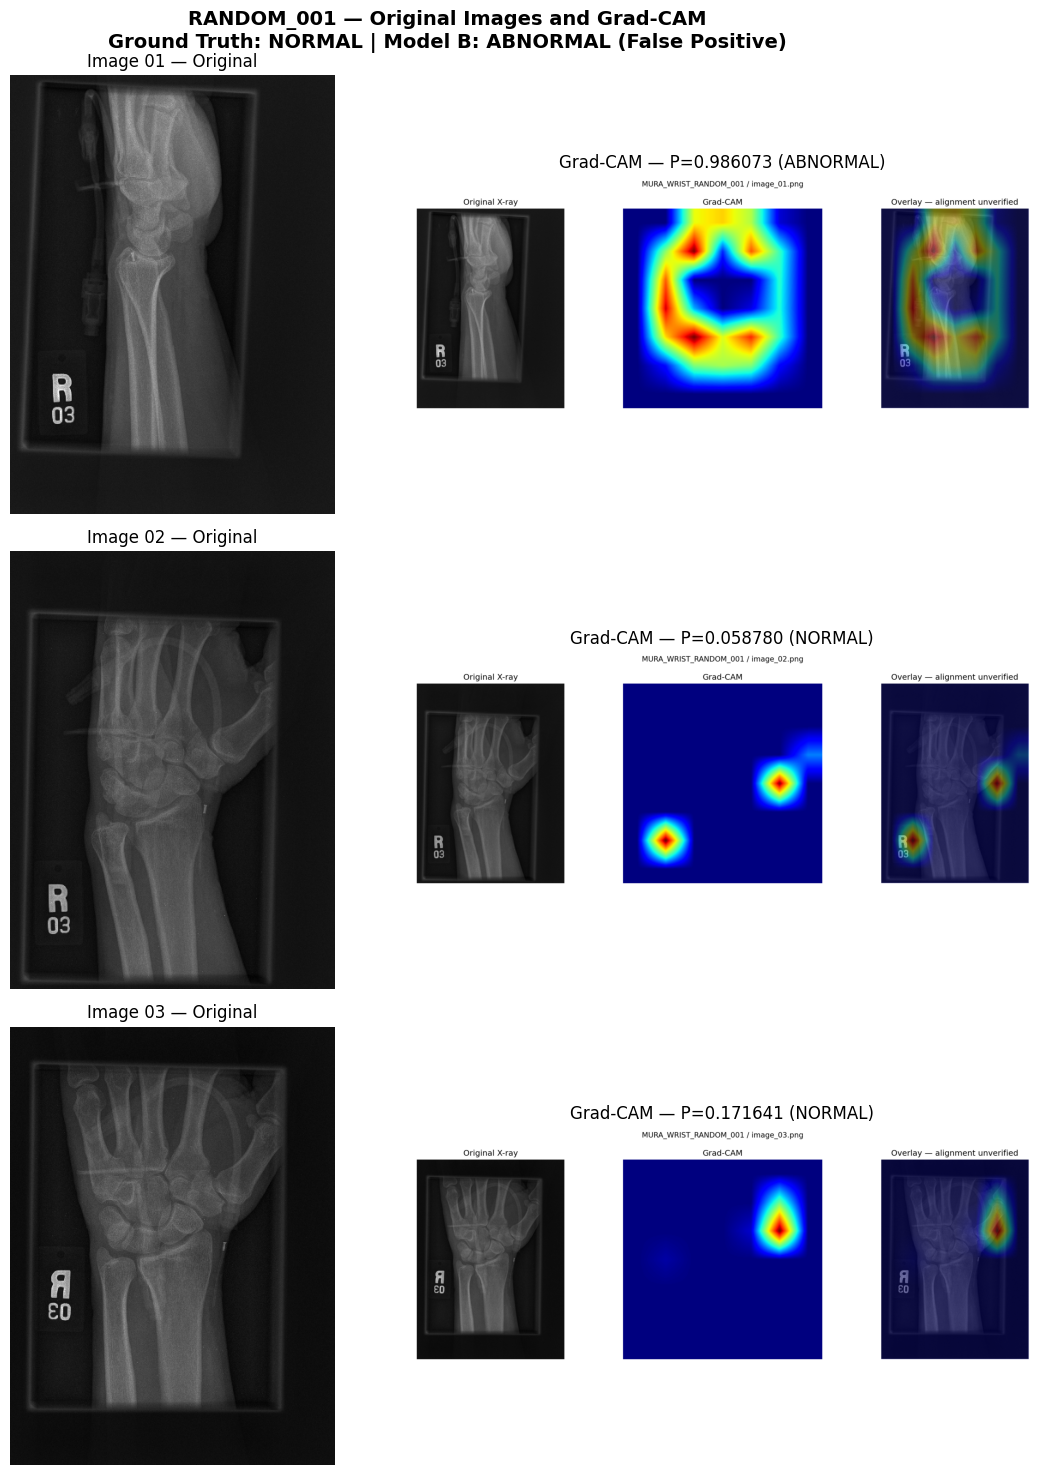

STEP 9B COMPLETE — Visual comparison displayed.


In [ ]:
# @title

# ============================================================
# STEP 9B — RANDOM_001 ORIGINAL VS GRAD-CAM
# Visualization only — no model inference
# ============================================================

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

STUDY_ID = "MURA_WRIST_RANDOM_001"
study_dir = GRADCAM_DIR / STUDY_ID

probabilities = [0.986073, 0.058780, 0.171641]
threshold = 0.263567715883255

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(12, 15)
)

for i in range(3):

    image_number = i + 1

    original_path = (
        study_dir / f"image_{image_number:02d}_original.png"
    )

    gradcam_path = (
        study_dir / f"image_{image_number:02d}_gradcam.png"
    )

    assert original_path.is_file(), original_path
    assert gradcam_path.is_file(), gradcam_path

    with Image.open(original_path) as img:
        original = img.copy()

    with Image.open(gradcam_path) as img:
        gradcam = img.copy()

    prediction = (
        "ABNORMAL"
        if probabilities[i] >= threshold
        else "NORMAL"
    )

    axes[i, 0].imshow(original, cmap="gray")
    axes[i, 0].set_title(
        f"Image {image_number:02d} — Original",
        fontsize=12
    )

    axes[i, 1].imshow(gradcam)
    axes[i, 1].set_title(
        f"Grad-CAM — P={probabilities[i]:.6f} "
        f"({prediction})",
        fontsize=12
    )

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle(
    "RANDOM_001 — Original Images and Grad-CAM\n"
    "Ground Truth: NORMAL | Model B: ABNORMAL (False Positive)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("STEP 9B COMPLETE — Visual comparison displayed.")


### STEP 9 — Key Finding: Agentic Workflow Verification

The analysis of `MURA_WRIST_RANDOM_001` demonstrates the added value of the agentic workflow beyond the classification performed by Model B.

The frozen Model B produced substantially different image-level probabilities (0.986073, 0.058780, and 0.171641), resulting in `image_threshold_disagreement = True`.

Although the aggregated study probability (0.405498) exceeded the frozen classification threshold (0.263568), producing an **ABNORMAL** prediction, the original MURA ground truth was **NORMAL**, making this a **False Positive**.

The deterministic workflow selected `priority_human_review` and authorized the explanatory tools. The CrewAI agent successfully executed both **Grad-CAM** and **Test-Time Augmentation (TTA)**, as documented in the Notebook 09 research report.

Importantly, the original Model B classification, frozen threshold, and model parameters remained unchanged.

**Key conclusion:** The agentic workflow successfully identified an image-level disagreement condition, followed the deterministic review policy, and executed additional explanatory tools without modifying the original model prediction.

This demonstrates the value of **policy-guided agentic tool orchestration**, in which the agent supports transparency, uncertainty assessment, and human review rather than independently changing diagnostic classifications.

*The documented execution confirms the disagreement, selected policy action, and successful tool execution. Establishing disagreement as the exact triggering condition requires verification of the deterministic policy implementation.*

## STEP 10 — Final Verification Summary and Conclusions

### 10.1 Independent Model B Reproducibility

The frozen Model B was independently loaded and evaluated using the original checkpoint, canonical preprocessing pipeline, frozen classification threshold, and mean-probability study aggregation.

Independent inference was performed without CrewAI, Gemini, or agent tools.

All eight image-level probabilities were reproduced within numerical tolerance, confirming the reproducibility of the recorded Model B predictions.

### 10.2 Study-Level Verification Results

| Study | Ground Truth | Model B Prediction | Outcome |
|---|---|---|---|
| MURA_WRIST_RANDOM_001 | NORMAL | ABNORMAL | False Positive |
| MURA_WRIST_RANDOM_002 | ABNORMAL | ABNORMAL | True Positive |
| MURA_WRIST_NO_TOOLS_001 | NORMAL | NORMAL | True Negative |

The original MURA study mappings were documented, and the two NO_TOOLS images were independently verified against the original MURA ZIP archive using pixel-level comparison.

### 10.3 Agentic Workflow Verification

`MURA_WRIST_RANDOM_001` demonstrated substantial image-level prediction disagreement.

The deterministic workflow selected `priority_human_review`, and the CrewAI agent successfully executed both Grad-CAM and Test-Time Augmentation (TTA).

The original Model B classification remained unchanged.

The documented execution supports successful policy-guided tool orchestration. Verification of the exact policy trigger requires inspection of the deterministic policy implementation.

### 10.4 Scientific Interpretation

The independent verification confirms that Model B predictions are reproducible outside the agentic workflow.

The RANDOM_001 false-positive case illustrates the distinction between model classification and agentic workflow management.

The agent did not correct or override the classification. Instead, it supported additional investigation and human review through authorized explanatory tools.

Grad-CAM and TTA provide supplementary research information but do not independently establish diagnostic correctness.

### 10.5 Final Conclusion

**The independent verification successfully reproduced the frozen Model B predictions and corroborated the previously documented agentic workflow execution in Notebook 09**

The principal contribution of the agentic component is not improved classification accuracy, but the ability to coordinate additional analysis and human-review workflows while preserving the original model prediction.

### Limitations

This verification covers three selected studies and does not constitute a comprehensive evaluation of Model B performance on the official MURA validation dataset.

The workflow is intended for research purposes only and does not replace clinical interpretation or human decision-making.